In [2]:
#pip install statsmodels

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import matplotlib.pyplot as plt
import statsmodels.api as sm


In [4]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers.dropna()

In [5]:
archivo = "amz_uk_price_prediction_dataset.csv"
df = pd.read_csv(archivo)

In [6]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Part 1: Analyzing Best-Seller Trends Across Product Categories
 --> Objective: Understand the relationship between product categories and their best-seller status.

### Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

In [7]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

In [8]:
best_seller = df.groupby('category')['isBestSeller'].mean().sort_values(ascending=False)

In [9]:
best_seller.head(5)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Name: isBestSeller, dtype: float64

#### Are there categories where being a best-seller is more prevalent?
Parece que sí, que Grocery, Smart Home Security & Lighting, y Health & Personal Care son aquellos productos que las personas compran frecuentemente y tienen por tanto más proporción de best sellers. 

### Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [10]:
chi2_contingency(crosstab_result)

Chi2ContingencyResult(statistic=np.float64(36540.20270061387), pvalue=np.float64(0.0), dof=295, expected_freq=array([[2.47190130e+02, 8.09870149e-01],
       [4.05371878e+03, 1.32812173e+01],
       [2.49183599e+02, 8.16401360e-01],
       [1.69145827e+03, 5.54173243e+00],
       [2.53170536e+02, 8.29463782e-01],
       [8.50214439e+03, 2.78556144e+01],
       [1.06650580e+02, 3.49419782e-01],
       [2.57157474e+02, 8.42526204e-01],
       [9.51781673e+03, 3.11832664e+01],
       [1.50008526e+04, 4.91473619e+01],
       [9.32544700e+03, 3.05530045e+01],
       [2.38219520e+02, 7.80479700e-01],
       [3.22941944e+03, 1.05805616e+01],
       [9.44704859e+03, 3.09514084e+01],
       [6.68808779e+03, 2.19122125e+01],
       [5.26275760e+02, 1.72423967e+00],
       [1.90296531e+04, 6.23469391e+01],
       [2.77191835e+03, 9.08164873e+00],
       [2.53170536e+02, 8.29463782e-01],
       [4.04674164e+02, 1.32583581e+00],
       [1.92489346e+04, 6.30653723e+01],
       [3.10482764e+03, 1.017

In [11]:
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

In [12]:
chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

Compute Cramér's V to understand the strength of association between best-seller status and category.

In [13]:
association(crosstab_result, method="cramer")

0.1222829439760564

### Visualizations:  
Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Axes: xlabel='category'>

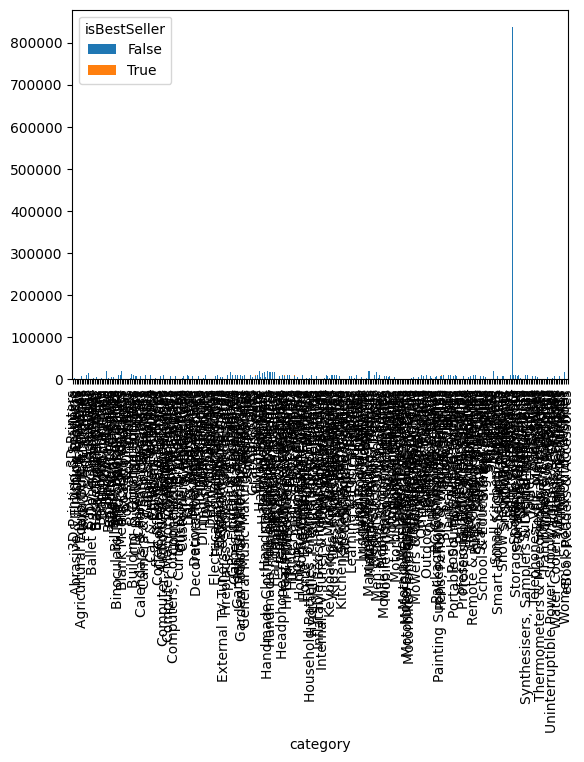

In [14]:
crosstab_result.plot(kind="bar", stacked=True)

<Axes: xlabel='category'>

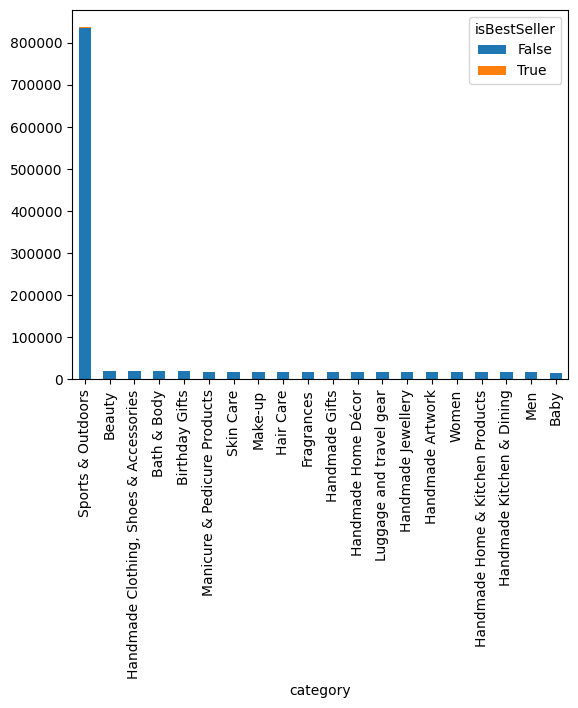

In [15]:
top_20 = crosstab_result.sum(axis=1).sort_values(ascending=False).head(20).index
crosstab_result.loc[top_20].plot(kind="bar", stacked=True)

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

### 0. Preliminary Step: Remove outliers in product prices.

In [16]:
df['price'] = tukeys_test_outliers(df[['price']])

### 1. Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.


In [17]:
top_20_categories = df['category'].value_counts().head(20)
top_20_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Handmade Gifts                             18295
Handmade Home Décor                        18146
Luggage and travel gear                    18142
Handmade Jewellery                         18044
Handmade Artwork                           17878
Women                                      17772
Handmade Home & Kitchen Products           17435
Handmade Kitchen & Dining                  17432
Men                                        17417
Baby                                       15050
Name: count

In [18]:
df_filtered = df[df['category'].isin(top_20_categories.index)]

In [19]:
df_final = df_filtered[df_filtered['price'] < 150]

/var/folders/bk/hzstscb16rn4p883jsg8t31c0000gn/T/ipykernel_29990/686039970.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_final, x='category', y='price', palette="coolwarm")


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'Handmade Home & Kitchen Products'),
  Text(1, 0, 'Sports & Outdoors'),
  Text(2, 0, 'Handmade Gifts'),
  Text(3, 0, 'Fragrances'),
  Text(4, 0, 'Skin Care'),
  Text(5, 0, 'Birthday Gifts'),
  Text(6, 0, 'Handmade Kitchen & Dining'),
  Text(7, 0, 'Bath & Body'),
  Text(8, 0, 'Manicure & Pedicure Products'),
  Text(9, 0, 'Beauty'),
  Text(10, 0, 'Handmade Artwork'),
  Text(11, 0, 'Make-up'),
  Text(12, 0, 'Baby'),
  Text(13, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(14, 0, 'Handmade Home Décor'),
  Text(15, 0, 'Men'),
  Text(16, 0, 'Luggage and travel gear'),
  Text(17, 0, 'Handmade Jewellery'),
  Text(18, 0, 'Women'),
  Text(19, 0, 'Hair Care')])

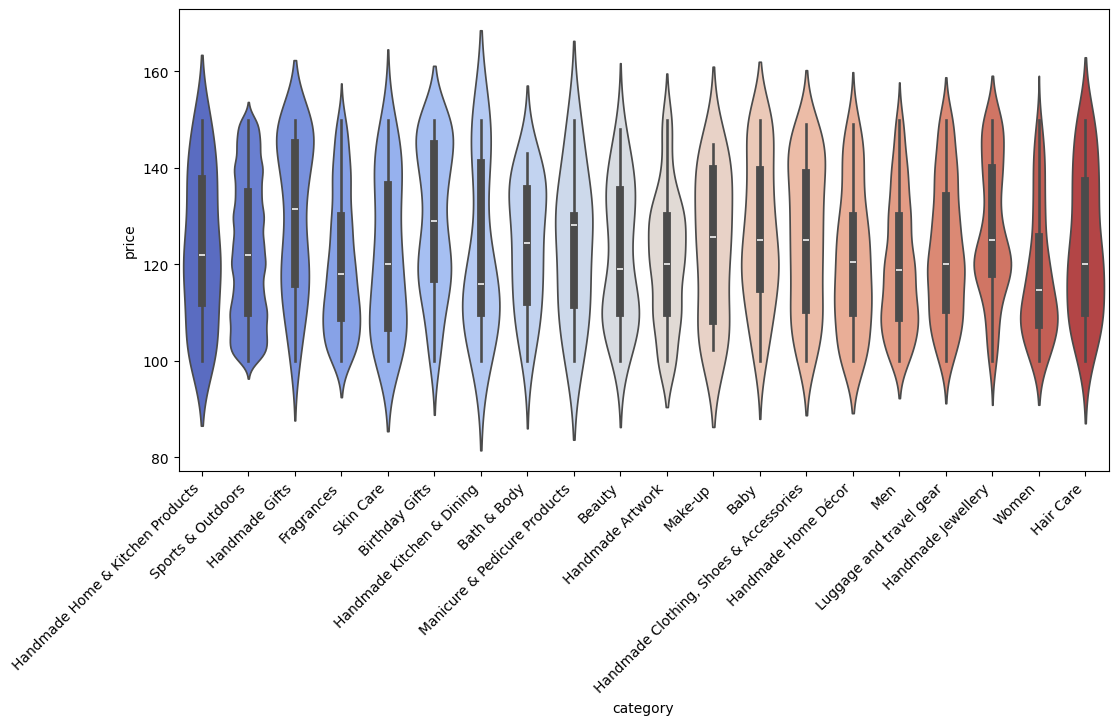

In [20]:
plt.figure(figsize=(12, 6))
sns.violinplot(data=df_final, x='category', y='price', palette="coolwarm")
plt.xticks(rotation=45, ha='right')

Which product category tends to have the highest median price? Don't filter here by top categories.

La categoría de Birthday gifts tiende a tener el precio mediano más alto. 

### 2. Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

In [21]:
top_10 = df_final['category'].value_counts().head(10).index

In [22]:
df_bar = df[df['category'].isin(top_10)]

/var/folders/bk/hzstscb16rn4p883jsg8t31c0000gn/T/ipykernel_29990/1723614691.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_bar, x='category', y='price', palette="coolwarm", estimator='mean')


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Fragrances'),
  Text(2, 0, 'Birthday Gifts'),
  Text(3, 0, 'Handmade Artwork'),
  Text(4, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(5, 0, 'Handmade Home Décor'),
  Text(6, 0, 'Men'),
  Text(7, 0, 'Luggage and travel gear'),
  Text(8, 0, 'Handmade Jewellery'),
  Text(9, 0, 'Women')])

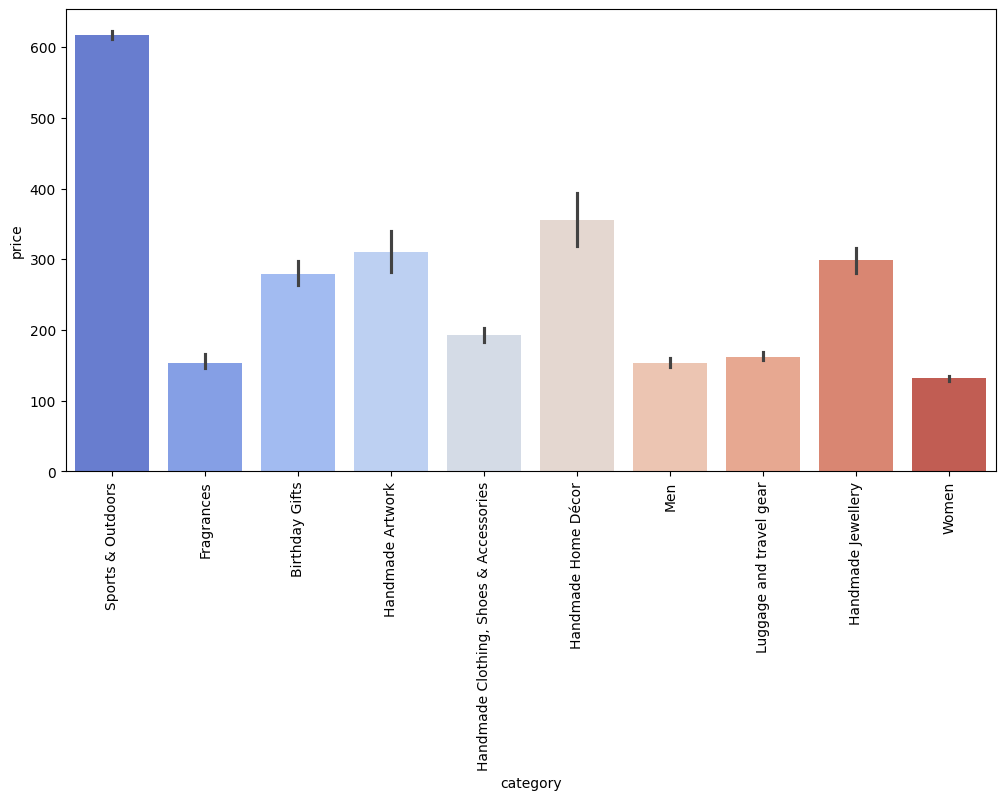

In [23]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df_bar, x='category', y='price', palette="coolwarm", estimator='mean')
plt.xticks(rotation=90)

Which product category commands the highest average price? Don't filter here by top categories.

In [24]:
avg_prices_sorted = df.groupby('category')['price'].mean().sort_values(ascending=False)
highest_avg_category = avg_prices_sorted.index[0]
highest_price = avg_prices_sorted.iloc[0]
highest_avg_category

'Billiard, Snooker & Pool'

### 3. Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.


/var/folders/bk/hzstscb16rn4p883jsg8t31c0000gn/T/ipykernel_29990/1827811516.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_bar, x='category', y='stars', palette="coolwarm")


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Fragrances'),
  Text(2, 0, 'Birthday Gifts'),
  Text(3, 0, 'Handmade Artwork'),
  Text(4, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(5, 0, 'Handmade Home Décor'),
  Text(6, 0, 'Men'),
  Text(7, 0, 'Luggage and travel gear'),
  Text(8, 0, 'Handmade Jewellery'),
  Text(9, 0, 'Women')])

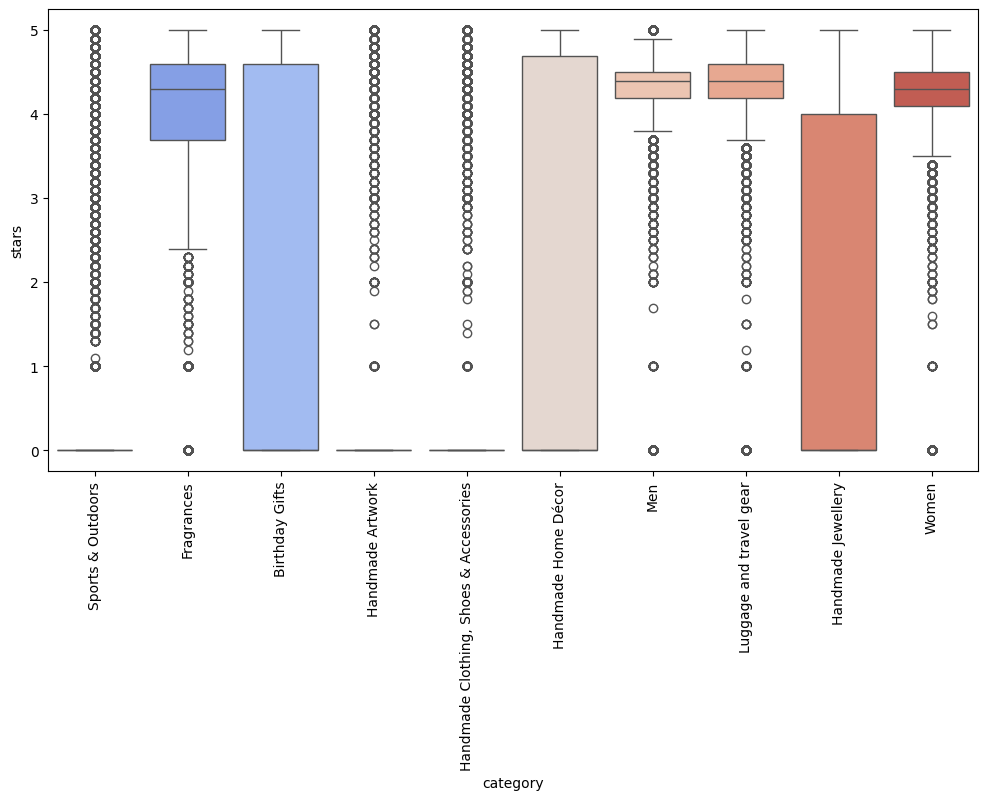

In [25]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_bar, x='category', y='stars', palette="coolwarm")
plt.xticks(rotation=90)

Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [26]:
avg_stars_sorted = df.groupby('category')['stars'].mean().sort_values(ascending=False)
highest_avg_category = avg_stars_sorted.index[0]
highest_price = avg_stars_sorted.iloc[0]
highest_avg_category

'Luxury Food & Drink'

## Part 3: Investigating the Interplay Between Product Prices and Ratings

Objective: Analyze how product ratings (stars) correlate with product prices.

### 1. Correlation Coefficients:

Calculate the correlation coefficient between price and stars.

In [27]:
correlation = df['price'].corr(df['stars'])
correlation

np.float64(-0.1765482245338288)

Is there a significant correlation between product price and its rating?


In [28]:
## No hay una correlación fuerte entre el precio y las estrellas, lo que sugiere que el precio no es un buen predictor ni incentivo para los ratings.

### Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

In [29]:
df_corr = df[['price', 'stars']]

In [30]:
df_corr_final = df_corr[df_corr['price'] < 15000]

<Axes: xlabel='price', ylabel='stars'>

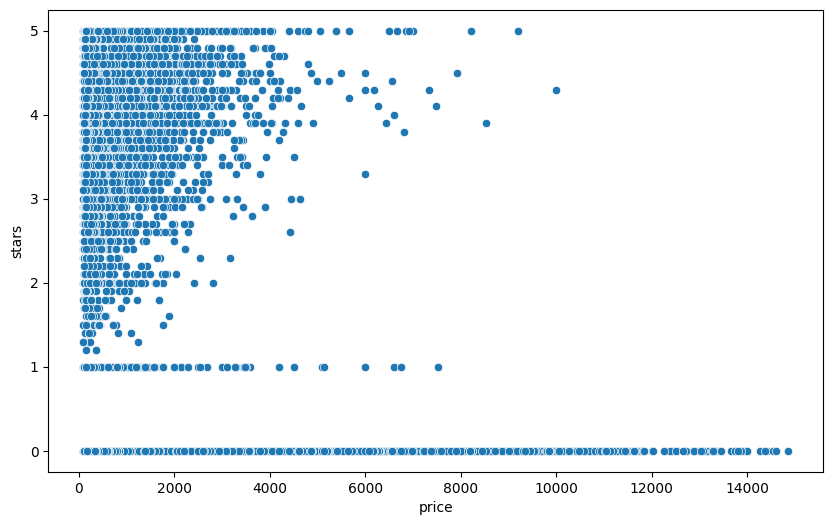

In [31]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_corr_final, x='price', y='stars', alpha=1)

Use a correlation heatmap to visualize correlations between all numerical variables.


In [32]:
df_numerical = df.select_dtypes(include=["number"])

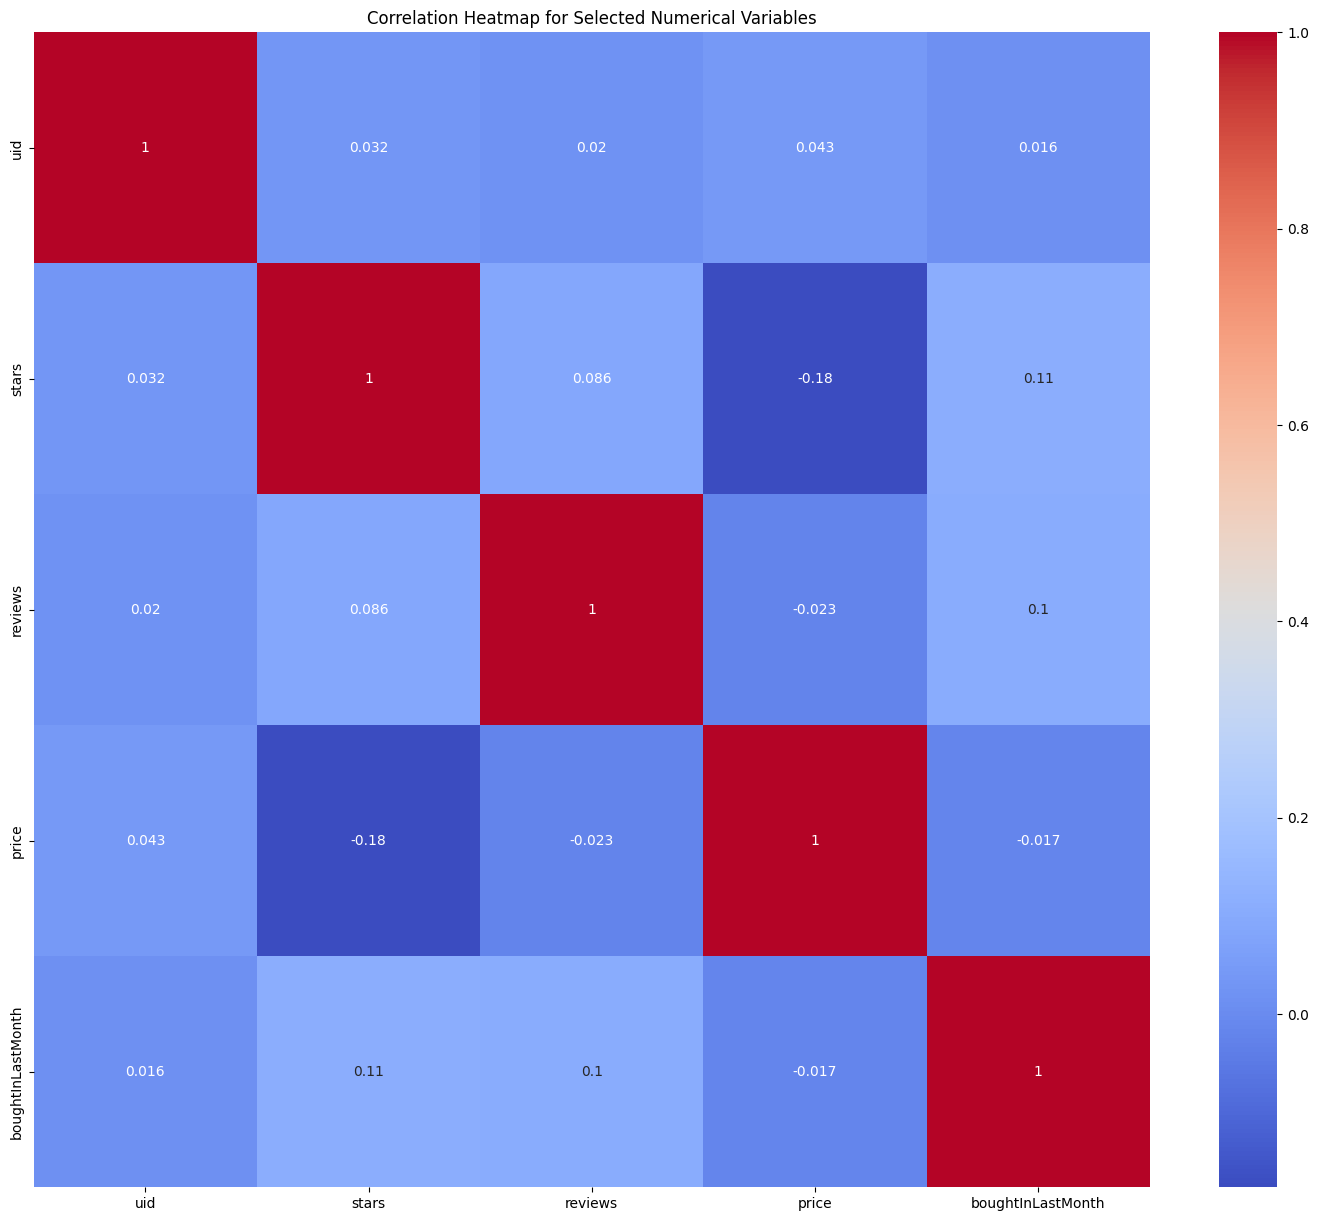

In [33]:
correlation_matrix = df_numerical.corr()
plt.figure(figsize=(18, 15))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

Examine if product prices typically follow a normal distribution using a QQ plot.


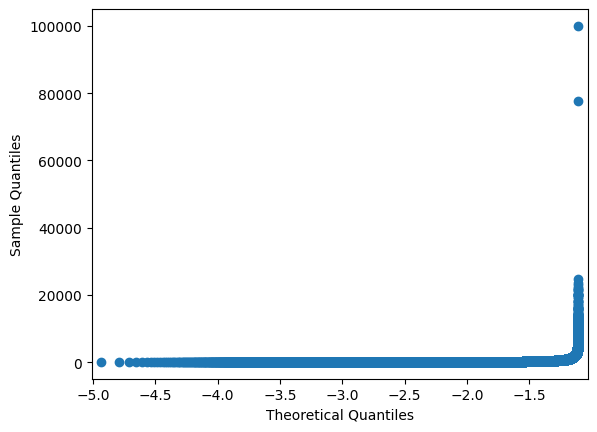

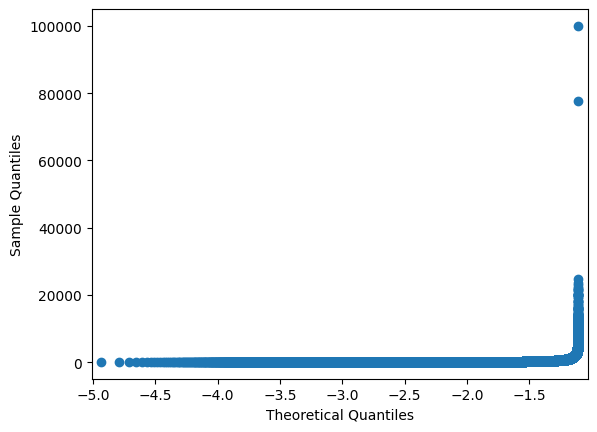

In [36]:
sm.qqplot(df['price'], line='s')